In [1]:
# Setup: imports and paths
import sys
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import os

# Add current directory to Python path for imports
current_dir = Path.cwd()
if str(current_dir) not in sys.path:
    sys.path.insert(0, str(current_dir))

# Import our benchmarking functions
from run_lab_proj_bench import run_bench, pick_default_executable

# Set up paths
if current_dir.name == 'analysis':
    repo_root = current_dir.parent
else:
    repo_root = current_dir

exe_path = pick_default_executable(repo_root)
print(f"Repository root: {repo_root}")
print(f"Executable path: {exe_path}")
print(f"Executable exists: {exe_path.exists()}")

# Configure matplotlib
plt.style.use('default')
plt.rcParams['figure.figsize'] = (12, 8)
plt.rcParams['font.size'] = 11


Repository root: D:\App External Data\Projects\VUB-ACS-25_GPU
Executable path: D:\App External Data\Projects\VUB-ACS-25_GPU\bin\lab_proj.exe
Executable exists: True


In [2]:
# Configuration
sizes = [1000*1.5**i for i in range(15)]


In [3]:
# Helper function to run benchmark and get results
def quick_bench(kernel, sizes, float_type=32, reps=1, elements_per_thread=1):
    result = run_bench(
        kernel=kernel,
        sizes=sizes,
        repetitions=reps,
        float_type=float_type,
        runs_per_size=5,
        exe=exe_path,
        make_plots=False,
        verbose=False,
        elements_per_thread=elements_per_thread
    )
    return result['aggregates']


In [4]:
# 1. SUM vs FMA comparison (single rep, different sizes)
print("🔄 1. SUM vs FMA comparison...")

sum_results = quick_bench("sum", sizes)
fma_results = quick_bench("fma", sizes)
len(fma_results), len(sum_results)

🔄 1. SUM vs FMA comparison...


(15, 15)

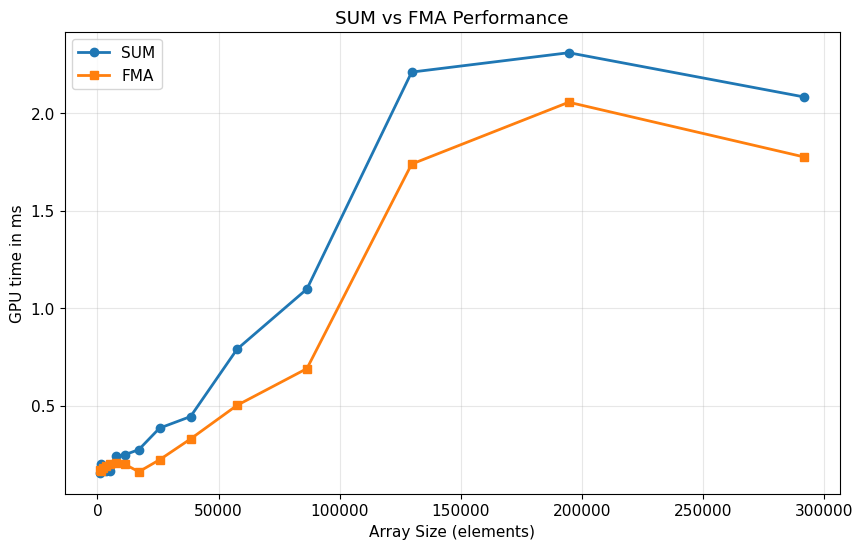

FMA advantage: 0.80x


In [5]:
plt.figure(figsize=(10, 6))
sizes_plot = [r['size'] for r in sum_results]
sum_gops = [r['host_ms_median'] for r in sum_results]
fma_gops = [r['host_ms_median'] for r in fma_results]

plt.plot(sizes_plot, sum_gops, '-o', label='SUM', linewidth=2)
plt.plot(sizes_plot, fma_gops, '-s', label='FMA', linewidth=2)
plt.xlabel('Array Size (elements)')
# plt.ylabel('Throughput (GOPS)')
plt.ylabel('GPU time in ms')
plt.title('SUM vs FMA Performance')
plt.legend()
plt.grid(True, alpha=0.3)
plt.savefig('sum_vs_fma.png', dpi=300, bbox_inches='tight')
plt.show()

print(f"FMA advantage: {np.mean(fma_gops)/np.mean(sum_gops):.2f}x")


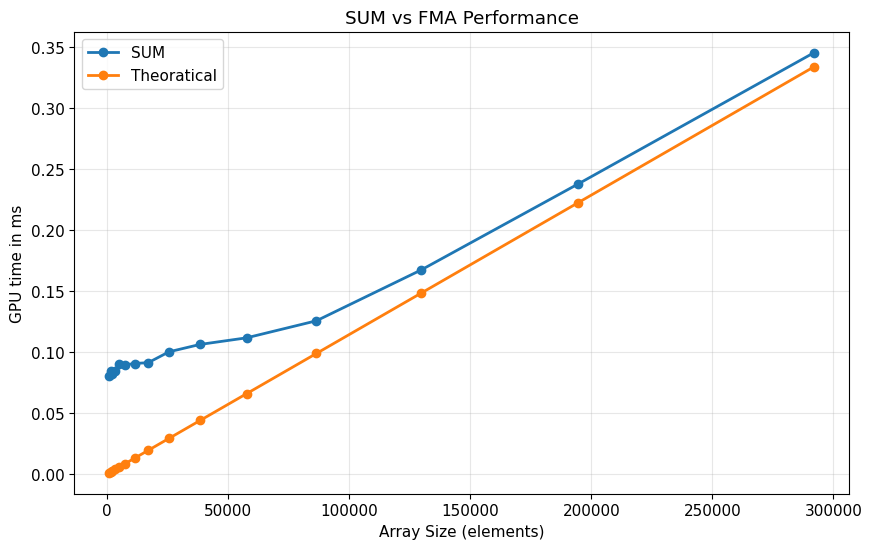

In [83]:
# sum_results = quick_bench("sum", sizes)

plt.figure(figsize=(10, 6))
sizes_plot = [r['size'] for r in sum_results]
sum_gops = [r['gpu_ms_median'] for r in sum_results]
mem_time_ms_per_elem= (2+1)*4 / (1.05*1e9)  # 2 reads + 1 write, float32
ops_time_ms_per_elem = 8 / (84.05*1e9) # time per TERA operations
Theoratical = [(mem_time_ms_per_elem+ops_time_ms_per_elem)*r for r in sizes_plot]
plt.plot(sizes_plot, sum_gops, '-o', label='SUM', linewidth=2)
plt.plot(sizes_plot, Theoratical, '-o', label='Theoratical', linewidth=2)
plt.xlabel('Array Size (elements)')
plt.ylabel('GPU time in ms')
plt.title('SUM vs FMA Performance')
plt.legend()
plt.grid(True, alpha=0.3)
plt.savefig('sum_vs_fma.png', dpi=300, bbox_inches='tight')
plt.show()


Analyzing performance vs kernel size...
  Processing kernel size: (3, 3, 5)
cpu_or_gpu='gpu'
Sample 1 of 3
Sample 2 of 3
Sample 3 of 3
  Processing kernel size: (5, 5, 5)
cpu_or_gpu='gpu'
Sample 1 of 3
Sample 2 of 3
Sample 3 of 3
  Processing kernel size: (7, 7, 5)
cpu_or_gpu='gpu'
Sample 1 of 3
Sample 2 of 3
Sample 3 of 3
  Processing kernel size: (9, 9, 5)
cpu_or_gpu='gpu'
Sample 1 of 3
Sample 2 of 3
Sample 3 of 3
  Processing kernel size: (11, 11, 5)
cpu_or_gpu='gpu'
Sample 1 of 3
Sample 2 of 3
Sample 3 of 3


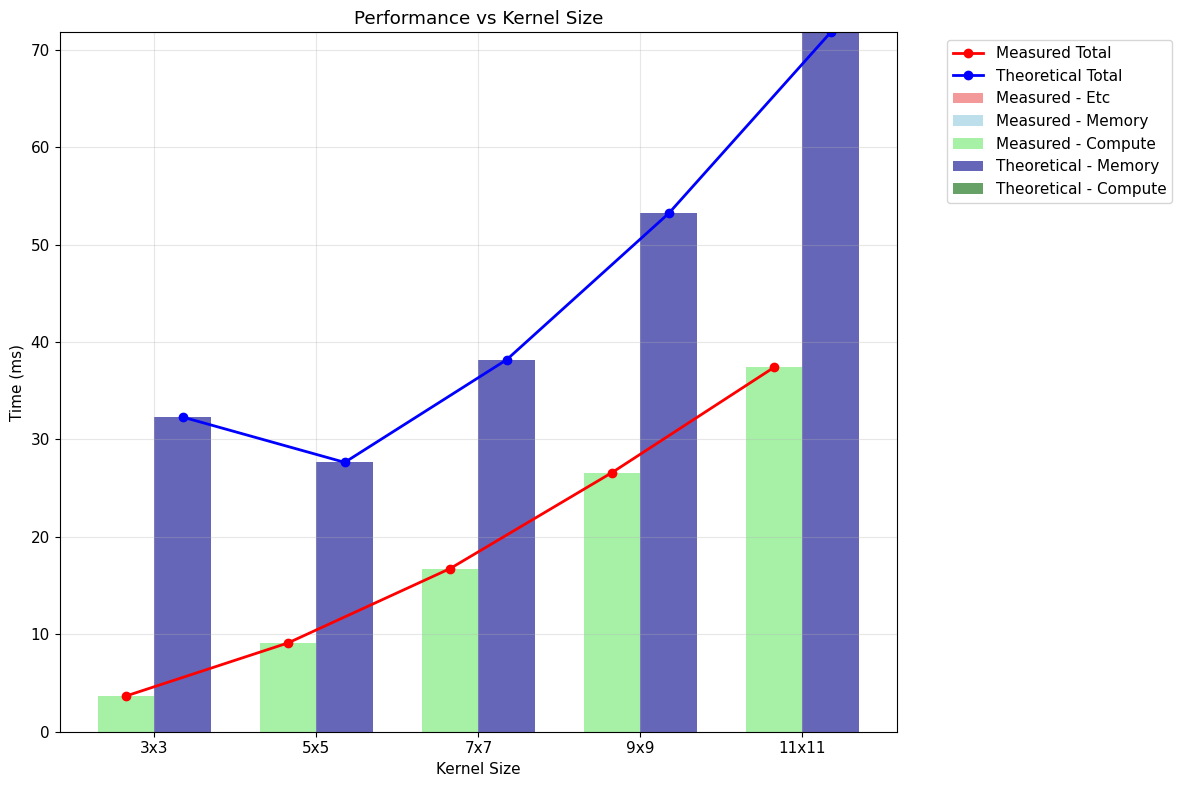

Analyzing performance vs input size...
  Processing input size: (200, 200, 20)
cpu_or_gpu='gpu'
Sample 1 of 3
Sample 2 of 3
Sample 3 of 3
  Processing input size: (400, 400, 20)
cpu_or_gpu='gpu'
Sample 1 of 3
Sample 2 of 3
Sample 3 of 3
  Processing input size: (600, 600, 20)
cpu_or_gpu='gpu'
Sample 1 of 3
Sample 2 of 3
Sample 3 of 3
  Processing input size: (800, 800, 20)
cpu_or_gpu='gpu'
Sample 1 of 3
Sample 2 of 3
Sample 3 of 3
  Processing input size: (1000, 1000, 20)
cpu_or_gpu='gpu'
Sample 1 of 3
Sample 2 of 3
Sample 3 of 3


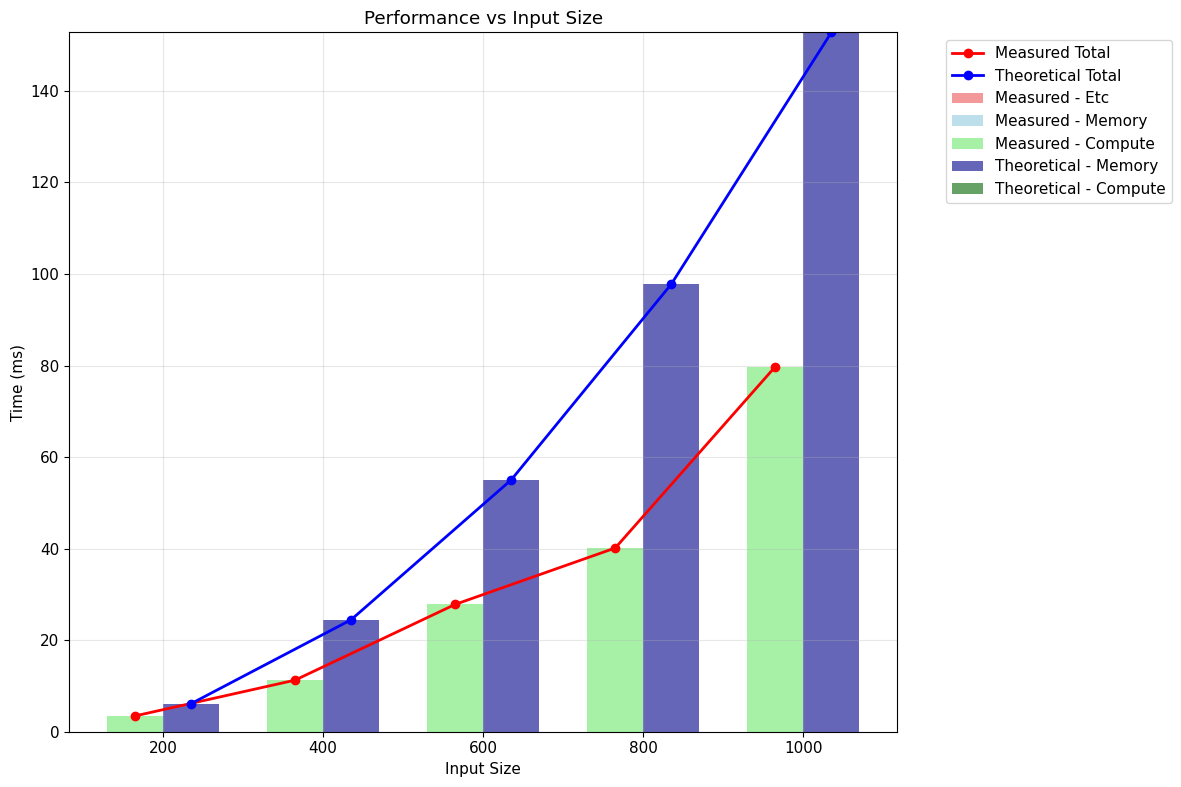


🚀 Running GPU Kernel Performance Analysis
🔄 Running efficient vs inefficient kernel comparison...

📊 Testing: Overlapping Work
   Running efficient sum...
   Running inefficient sum_overlap...

📊 Testing: Strided Memory Access
   Running efficient sum...
   Running inefficient sum_strided...

📊 Testing: Branch Divergence
   Running efficient sum...
   Running inefficient sum_reverse...

📊 Testing: Redundant Memory Reads
   Running efficient sum...
   Running inefficient sum_redundant...

📊 Testing: FMA Overlapping Work
   Running efficient fma...
   Running inefficient fma_overlap...

📊 Testing: FMA Strided Access
   Running efficient fma...
   Running inefficient fma_strided...
🔄 Running elements per thread comparison...

🧵 Testing 1 elements per thread...

🧵 Testing 2 elements per thread...

🧵 Testing 4 elements per thread...

🧵 Testing 8 elements per thread...

🧵 Testing 16 elements per thread...

🧵 Testing 32 elements per thread...

🎉 GPU kernel analysis complete!
Analysis complet

In [89]:
from performance_analysis import analyze_kernel_size_performance, run_efficiency_comparison, \
    run_elements_per_thread_comparison, analyze_input_size_performance

kernel_measured, kernel_theoretical = analyze_kernel_size_performance()

# Run input size analysis
input_measured, input_theoretical = analyze_input_size_performance()

# Run GPU kernel efficiency comparisons if executable exists
if os.path.exists(exe_path):
    print("\n" + "="*60)
    print("🚀 Running GPU Kernel Performance Analysis")
    print("="*60)

    # Run efficiency comparison
    efficiency_results = run_efficiency_comparison()

    # Run elements per thread comparison
    elements_results = run_elements_per_thread_comparison()

    print("\n🎉 GPU kernel analysis complete!")
else:
    print(f"\n⚠️  GPU benchmark executable not found at {exe_path}")
    print("Skipping GPU kernel efficiency analysis.")

print("Analysis complete. Plots saved as PNG files.")


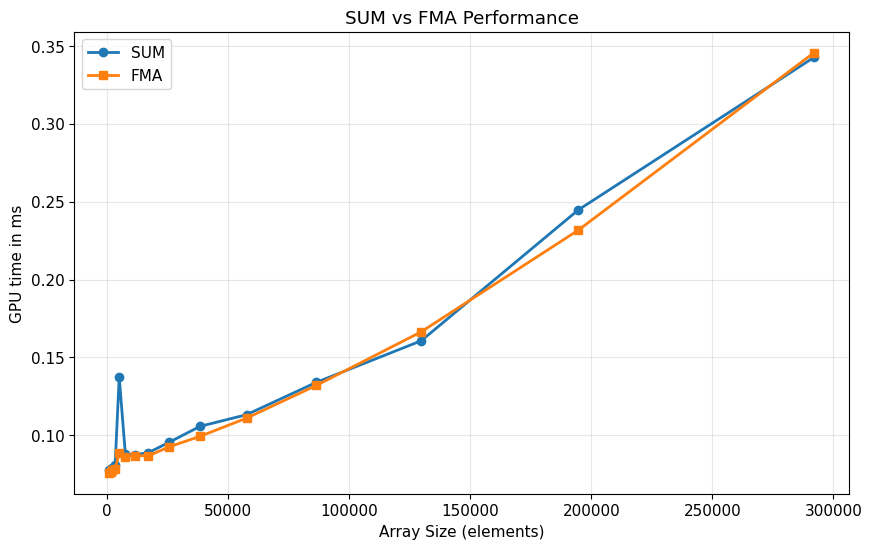

FMA advantage: 0.96x


In [44]:
plt.figure(figsize=(10, 6))
sizes_plot = [r['size'] for r in sum_results]
# sum_gops = [r['gops_median'] for r in sum_results]
# fma_gops = [r['gops_median'] for r in fma_results]
sum_gops = [r['gpu_ms_median'] for r in sum_results]
fma_gops = [r['gpu_ms_median'] for r in fma_results]

plt.plot(sizes_plot, sum_gops, '-o', label='SUM', linewidth=2)
plt.plot(sizes_plot, fma_gops, '-s', label='FMA', linewidth=2)
plt.xlabel('Array Size (elements)')
# plt.ylabel('Throughput (GOPS)')
plt.ylabel('GPU time in ms')
plt.title('SUM vs FMA Performance')
plt.legend()
plt.grid(True, alpha=0.3)
plt.savefig('sum_vs_fma.png', dpi=300, bbox_inches='tight')
plt.show()

print(f"FMA advantage: {np.mean(fma_gops)/np.mean(sum_gops):.2f}x")


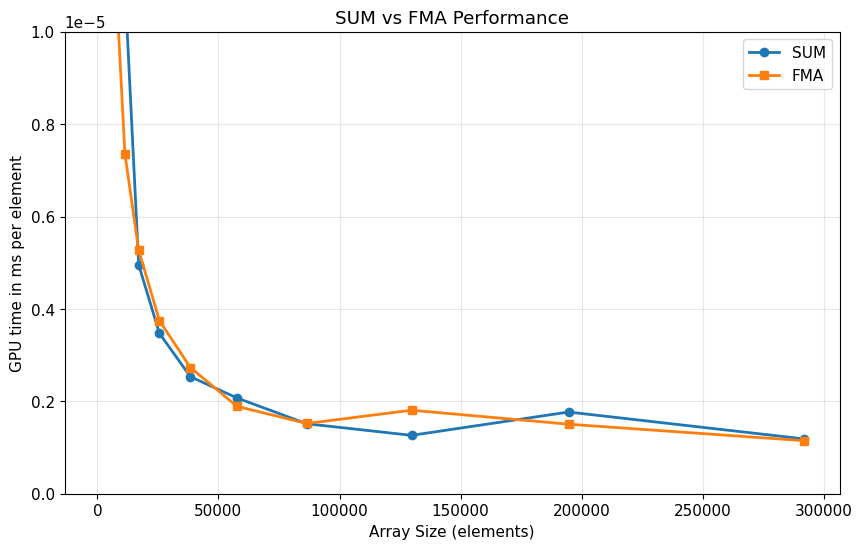

FMA advantage: 1.04x


In [11]:
plt.figure(figsize=(10, 6))
sizes_plot = [r['size'] for r in sum_results]
# sum_gops = [r['gops_median'] for r in sum_results]
# fma_gops = [r['gops_median'] for r in fma_results]
sum_gops = [r['gpu_ms_median']/r['size'] for r in sum_results]
fma_gops = [r['gpu_ms_median']/r['size'] for r in fma_results]

plt.plot(sizes_plot, sum_gops, '-o', label='SUM', linewidth=2)
plt.plot(sizes_plot, fma_gops, '-s', label='FMA', linewidth=2)
plt.xlabel('Array Size (elements)')
plt.ylabel('GPU time in ms per element')
plt.title('SUM vs FMA Performance')
plt.legend()
plt.grid(True, alpha=0.3)
plt.ylim(0,1e-5)
plt.savefig('sum_vs_fma.png', dpi=300, bbox_inches='tight')
plt.show()

print(f"FMA advantage: {np.mean(fma_gops)/np.mean(sum_gops):.2f}x")


🔄 2. Float16 vs Float32 comparison...


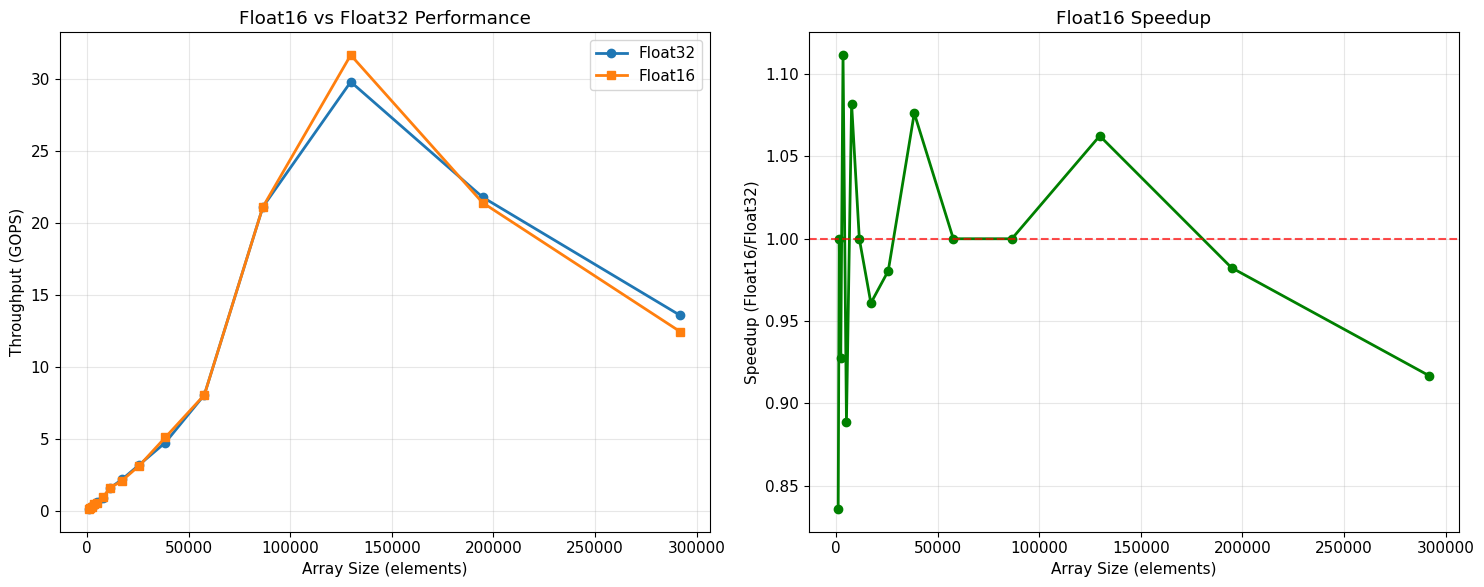

Average F16 speedup: 0.99x


In [14]:
# 2. Float16 vs Float32 comparison (SUM kernel)
print("🔄 2. Float16 vs Float32 comparison...")

f32_results = quick_bench("sum", sizes, float_type=32)
f16_results = quick_bench("sum", sizes, float_type=16)

# Check if we have results for both float types
if not f32_results:
    print("❌ No Float32 results obtained")
if not f16_results:
    print("❌ No Float16 results obtained - Float16 might not be supported")

if f32_results and f16_results:
    plt.figure(figsize=(15, 6))

    # Performance comparison
    plt.subplot(1, 2, 1)
    sizes_plot_f32 = [r['size'] for r in f32_results]
    sizes_plot_f16 = [r['size'] for r in f16_results]
    f32_gops = [r['gops_median'] for r in f32_results]
    f16_gops = [r['gops_median'] for r in f16_results]

    plt.plot(sizes_plot_f32, f32_gops, '-o', label='Float32', linewidth=2)
    plt.plot(sizes_plot_f16, f16_gops, '-s', label='Float16', linewidth=2)
    plt.xlabel('Array Size (elements)')
    plt.ylabel('Throughput (GOPS)')
    plt.title('Float16 vs Float32 Performance')
    plt.legend()
    plt.grid(True, alpha=0.3)

    # Speedup (only if both have same number of results)
    plt.subplot(1, 2, 2)
    if len(f16_gops) == len(f32_gops):
        speedup = [f16/f32 for f16, f32 in zip(f16_gops, f32_gops)]
        plt.plot(sizes_plot_f32, speedup, '-o', color='green', linewidth=2)
        plt.axhline(y=1.0, color='red', linestyle='--', alpha=0.7)
        plt.xlabel('Array Size (elements)')
        plt.ylabel('Speedup (Float16/Float32)')
        plt.title('Float16 Speedup')
        plt.grid(True, alpha=0.3)

        plt.tight_layout()
        plt.savefig('float16_vs_float32.png', dpi=300, bbox_inches='tight')
        plt.show()

        print(f"Average F16 speedup: {np.mean(speedup):.2f}x")
    else:
        plt.text(0.5, 0.5, 'Cannot compute speedup:\nDifferent number of results',
                ha='center', va='center', transform=plt.gca().transAxes)
        plt.title('Speedup (unavailable)')

        plt.tight_layout()
        plt.savefig('float16_vs_float32.png', dpi=300, bbox_inches='tight')
        plt.show()

        print("Cannot compute average speedup: different number of results")
else:
    print("Skipping Float16 vs Float32 comparison due to missing results")
    if f32_results:
        # Just plot Float32 results
        plt.figure(figsize=(10, 6))
        sizes_plot_f32 = [r['size'] for r in f32_results]
        f32_gops = [r['gops_median'] for r in f32_results]
        plt.plot(sizes_plot_f32, f32_gops, '-o', label='Float32 (only)', linewidth=2)
        plt.xlabel('Array Size (elements)')
        plt.ylabel('Throughput (GOPS)')
        plt.title('Float32 Performance (Float16 not available)')
        plt.legend()
        plt.grid(True, alpha=0.3)
        plt.savefig('float32_only.png', dpi=300, bbox_inches='tight')
        plt.show()


🔄 3. SUM vs FMA with different repetitions...


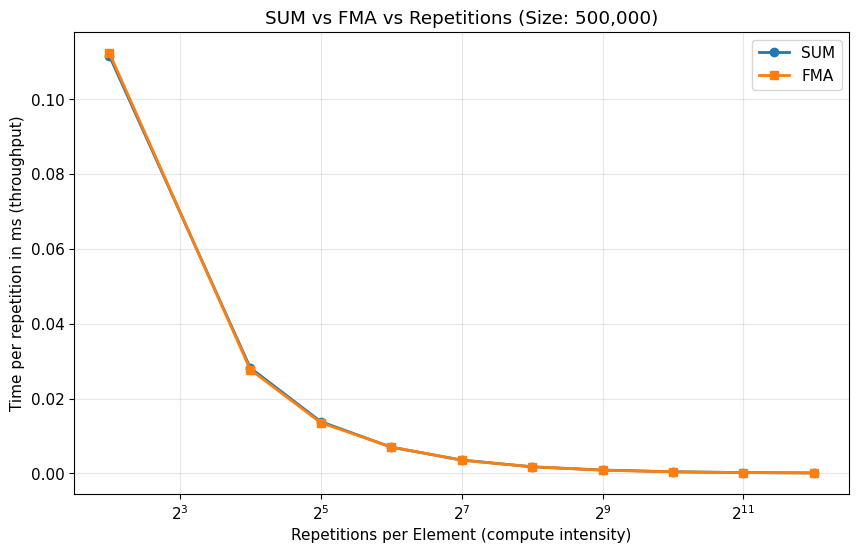

In [42]:
# 3. SUM vs FMA with different repetitions (large size)
print("🔄 3. SUM vs FMA with different repetitions...")

sum_reps_results = []
fma_reps_results = []

large_size=[500000]
reps_list = [4,16,32, 64, 128, 256, 512, 1024, 2048, 4096]
for reps in reps_list:
    sum_res = quick_bench("sum", large_size, reps=reps)
    fma_res = quick_bench("fma", large_size, reps=reps)
    sum_reps_results.append(sum_res[0]['gpu_ms_median']/reps)
    fma_reps_results.append(fma_res[0]['gpu_ms_median']/reps)

plt.figure(figsize=(10, 6))
plt.plot(reps_list, sum_reps_results, '-o', label='SUM', linewidth=2)
plt.plot(reps_list, fma_reps_results, '-s', label='FMA', linewidth=2)
plt.xscale('log', base=2)
plt.xlabel('Repetitions per Element (compute intensity)')
plt.ylabel('Time per repetition in ms (throughput)')
plt.title(f'SUM vs FMA vs Repetitions (Size: {large_size[0]:,})')
plt.legend()
plt.grid(True, alpha=0.3)
plt.savefig('sum_vs_fma_reps.png', dpi=300, bbox_inches='tight')
plt.show()


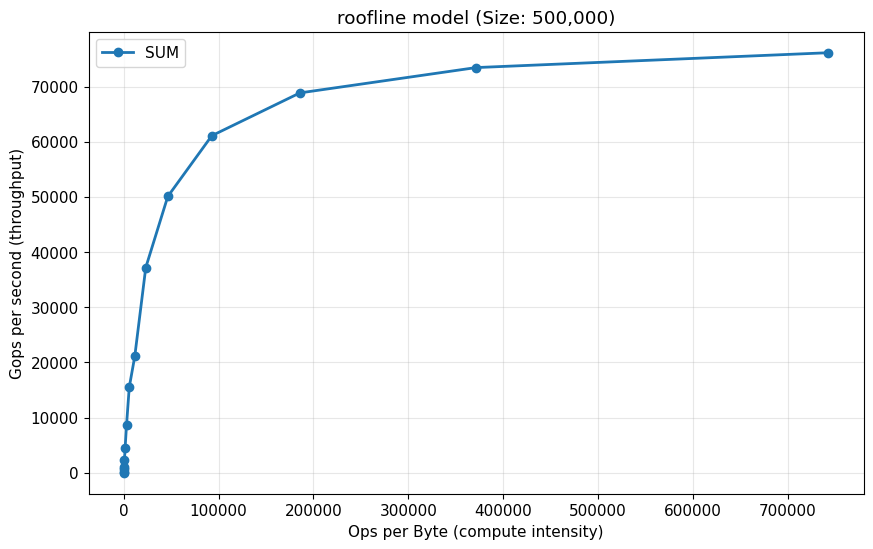

In [9]:

reps_list = [4, 64, 256, 512, 1024, 2048, 4096, 8192, 16384, 32768, 65536, 131072, 262144, 524288, 524288*2]
N = 500_000
bytes_per_elem = 3
flops_per_iter = 1+1+1/16+1/16  # 1 add + 1 assignment + 1 loop check every 16 iters + 1 loop count every 16 iters

ops_per_byte = []
gops_per_sec = []

for reps in reps_list:
    res = quick_bench("sum_reps", [N], reps=int(reps))   # ensure kernel arg is int
    time_s = res[0]['gpu_ms_median'] / 1e3

    flops_per_elem = flops_per_iter * reps
    intensity = flops_per_elem / bytes_per_elem
    throughput = (flops_per_elem / 1e9 * N) / time_s

    ops_per_byte.append(intensity)
    gops_per_sec.append(throughput)


plt.figure(figsize=(10, 6))
plt.plot(ops_per_byte, gops_per_sec, '-o', label='SUM', linewidth=2)
plt.xlabel('Ops per Byte (compute intensity)')
plt.ylabel('Gops per second (throughput)')
plt.title(f'roofline model (Size: {N:,})')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


In [8]:
import numpy as np
for s in range(1,32):
    idx = [i*s%32 for i in range(32)]
    temp=np.unique(idx)
    print(s, len(idx))
    if len(idx)!=32:
        print('*****************')

1 32
2 32
3 32
4 32
5 32
6 32
7 32
8 32
9 32
10 32
11 32
12 32
13 32
14 32
15 32
16 32
17 32
18 32
19 32
20 32
21 32
22 32
23 32
24 32
25 32
26 32
27 32
28 32
29 32
30 32
31 32


🔄 4. Multi-element vs Single element SUM...


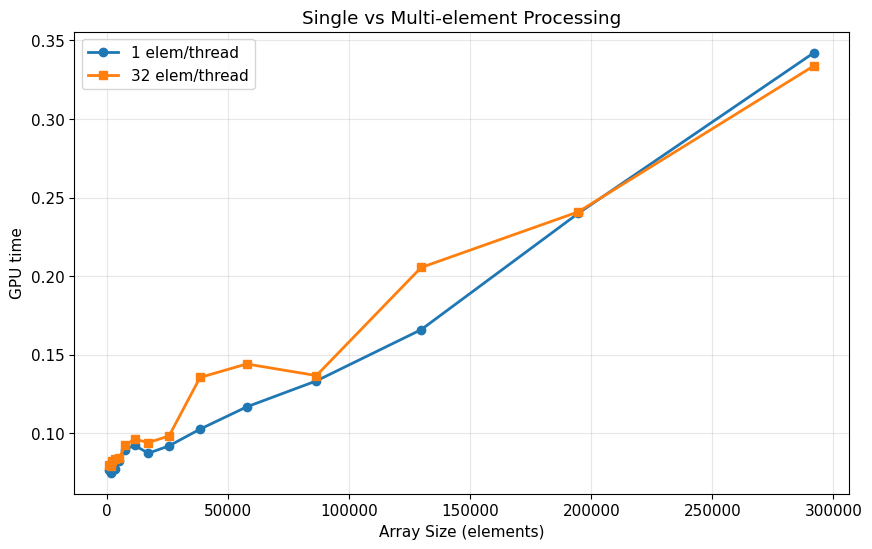

Multi-element speedup: 1.09x


In [15]:
# 4. Efficient multi-element vs single element SUM
print("🔄 4. Multi-element vs Single element SUM...")

single_results = quick_bench("sum", sizes, elements_per_thread=1)
multi_results = quick_bench("sum", sizes, elements_per_thread=32)

plt.figure(figsize=(10, 6))
single_gops = [r['gpu_ms_median'] for r in single_results]
multi_gops = [r['gpu_ms_median'] for r in multi_results]
sizes_plot = [r['size'] for r in sum_results]

plt.plot(sizes_plot, single_gops, '-o', label='1 elem/thread', linewidth=2)
plt.plot(sizes_plot, multi_gops, '-s', label='32 elem/thread', linewidth=2)
plt.xlabel('Array Size (elements)')
plt.ylabel('GPU time')
plt.title('Single vs Multi-element Processing')
plt.legend()
plt.grid(True, alpha=0.3)
plt.savefig('single_vs_multi_element.png', dpi=300, bbox_inches='tight')
plt.show()

speedup_multi = [multi/single for multi, single in zip(multi_gops, single_gops)]
print(f"Multi-element speedup: {np.mean(speedup_multi):.2f}x")


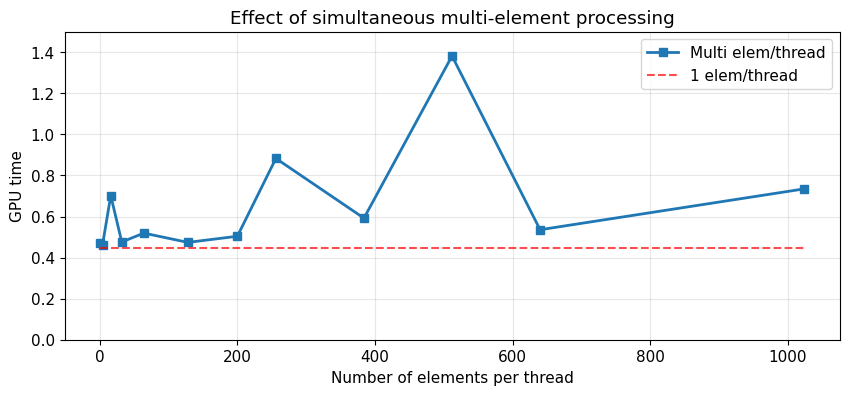

Multi-element speedup: 7.07x


In [35]:
# 4. Efficient multi-element vs single element SUM
# print("🔄 4. Multi-element vs Single element SUM...")
#
# elem_reps = [1,4,16,32,64,128,200,256, 512-128, 512, 512+128,1024]
# multi_results = [quick_bench("sum", [N], elements_per_thread=reps)[0] for reps in elem_reps]
#
plt.figure(figsize=(10, 4))
multi_gops = [r['gpu_ms_median'] for r in multi_results]
sizes_plot = elem_reps

plt.plot(sizes_plot, multi_gops, '-s', linewidth=2, label='Multi elem/thread')
plt.hlines(y=quick_bench("sum", [N])[0]['gpu_ms_median'], color='red', linestyle='--', alpha=0.7, label='1 elem/thread',
           xmin=0, xmax=max(sizes_plot))
plt.xlabel('Number of elements per thread')
plt.ylabel('GPU time')
plt.ylim(0,1.5)
plt.title('Effect of simultaneous multi-element processing')
plt.grid(True, alpha=0.3)
plt.legend()
plt.savefig('single_vs_multi_element.png', dpi=300, bbox_inches='tight')
plt.show()

speedup_multi = [multi/single for multi, single in zip(multi_gops, single_gops)]
print(f"Multi-element speedup: {np.mean(speedup_multi):.2f}x")


🔄 5. Efficient vs Inefficient kernels...
Overlapping Worker: 0.82x slower when inefficient


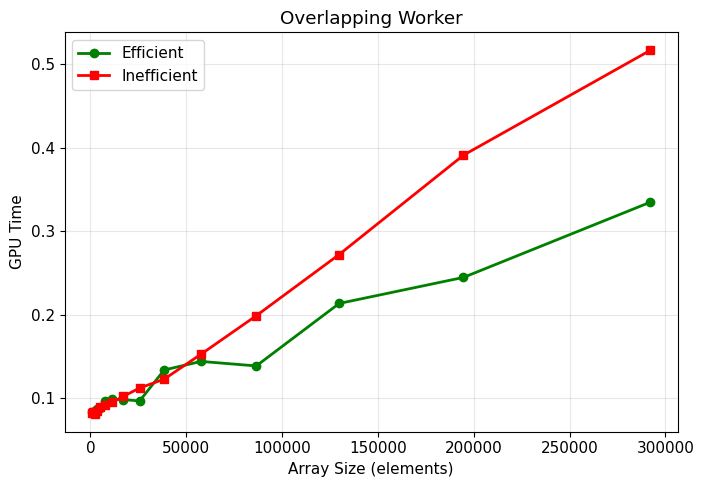

In [23]:
# 5. Efficient vs Inefficient kernels
print("🔄 5. Efficient vs Inefficient kernels...")

# Test available inefficient kernels
kernel_pairs = [
    ("sum", "sum_overlap", "Overlapping Worker"),
]

plt.figure(figsize=(20, 5))

for i, (efficient, inefficient, name) in enumerate(kernel_pairs):
    try:
        eff_results = quick_bench(efficient, sizes, elements_per_thread=32)
        ineff_results = quick_bench(inefficient, sizes, elements_per_thread=32)

        plt.subplot(1, 3, i+1)
        eff_gops = [r['gpu_ms_median'] for r in eff_results]
        ineff_gops = [r['gpu_ms_median'] for r in ineff_results]

        plt.plot(sizes_plot, eff_gops, '-o', label='Efficient', linewidth=2, color='green')
        plt.plot(sizes_plot, ineff_gops, '-s', label='Inefficient', linewidth=2, color='red')
        plt.xlabel('Array Size (elements)')
        plt.ylabel('GPU Time')
        plt.title(f'{name}')
        plt.legend()
        plt.grid(True, alpha=0.3)

        slowdown = np.mean(eff_gops) / np.mean(ineff_gops)
        print(f"{name}: {slowdown:.2f}x slower when inefficient")

    except Exception as e:
        print(f"Skipping {name}: {e}")

plt.tight_layout()
plt.savefig('efficient_vs_inefficient.png', dpi=300, bbox_inches='tight')
plt.show()


In [18]:
# Summary
print("\n🏆 Performance Summary:")
print(f"1. FMA vs SUM advantage: {np.mean(fma_gops)/np.mean(sum_gops):.2f}x")
print(f"2. Float16 vs Float32 speedup: {np.mean(speedup):.2f}x")
print(f"3. Multi-element processing speedup: {np.mean(speedup_multi):.2f}x")
print(f"4. Best single SUM performance: {max(single_gops):.2f} GOPS")
print(f"5. Best multi SUM performance: {max(multi_gops):.2f} GOPS")

print("\n✅ All comparisons complete!")



🏆 Performance Summary:
1. FMA vs SUM advantage: nanx
2. Float16 vs Float32 speedup: 0.99x
3. Multi-element processing speedup: 0.52x
4. Best single SUM performance: 29.38 GOPS
5. Best multi SUM performance: 16.56 GOPS

✅ All comparisons complete!
